# Eksploracyjna Analiza Danych (EDA) — Black Friday

Zestaw danych: [Black Friday (Kaggle)](https://www.kaggle.com/sdolezel/black-friday?select=train.csv)

**Spis treści**
1. Importowanie bibliotek
2. Ładowanie zestawu danych
3. Eksploracja danych strukturalnych
4. Obsługa duplikatów
5. Obsługa wartości odstających
6. Obsługa brakujących wartości
7. Analiza jednowymiarowa
8. Analiza dwuwymiarowa

## 1. Importowanie bibliotek języka Python

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

## 2. Ładowanie zestawu danych w języku Python

In [2]:
df = pd.read_csv('train.csv')
df

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969
...,...,...,...,...,...,...,...,...,...,...,...,...
550063,1006033,P00372445,M,51-55,13,B,1,1,20,NaN,NaN,368
550064,1006035,P00375436,F,26-35,1,C,3,0,20,NaN,NaN,371
550065,1006036,P00375436,F,26-35,15,B,4+,1,20,NaN,NaN,137
550066,1006038,P00375436,F,55+,1,C,2,0,20,NaN,NaN,365


## 3. Eksploracja danych strukturalnych

Pierwszy krok EDA — zrozumienie metadanych (Metadata).

### Pierwsze 5 obserwacji

In [3]:
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


### Ostatnie 5 obserwacji

In [4]:
df.tail()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
550063,1006033,P00372445,M,51-55,13,B,1,1,20,NaN,NaN,368
550064,1006035,P00375436,F,26-35,1,C,3,0,20,NaN,NaN,371
550065,1006036,P00375436,F,26-35,15,B,4+,1,20,NaN,NaN,137
550066,1006038,P00375436,F,55+,1,C,2,0,20,NaN,NaN,365
550067,1006039,P00371644,F,46-50,0,B,4+,1,20,NaN,NaN,490


### Liczba zmiennych i obserwacji

In [5]:
df.shape

(550068, 12)

In [6]:
print('Liczba obserwacji:', df.shape[0])
print('Liczba zmiennych:', df.shape[1])

Liczba obserwacji: 550068
Liczba zmiennych: 12


### Nazwy zmiennych i typy danych

In [7]:
df.dtypes

User_ID                         int64
Product_ID                        str
Gender                            str
Age                               str
Occupation                      int64
City_Category                     str
Stay_In_Current_City_Years        str
Marital_Status                  int64
Product_Category_1              int64
Product_Category_2            float64
Product_Category_3            float64
Purchase                        int64
dtype: object

### Liczba niebrakujących wartości dla każdej zmiennej

In [8]:
df.count()

User_ID                       550068
Product_ID                    550068
Gender                        550068
Age                           550068
Occupation                    550068
City_Category                 550068
Stay_In_Current_City_Years    550068
Marital_Status                550068
Product_Category_1            550068
Product_Category_2            376430
Product_Category_3            166821
Purchase                      550068
dtype: int64

### Statystyki opisowe

In [9]:
pd.set_option('display.max_columns', None)
df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068.000000,550068.000000,550068.000000,376430.000000,166821.000000,550068.000000
mean,1.003029e+06,8.076707,0.409653,5.404270,9.842329,12.668243,9263.968713
std,1.727592e+03,6.522660,0.491770,3.936211,5.086590,4.125338,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001516e+06,2.000000,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003077e+06,7.000000,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,15.000000,16.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [10]:
df.describe(include='all')

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068,550068,550068,550068.000000,550068,550068,550068.000000,550068.000000,376430.000000,166821.000000,550068.000000
unique,NaN,3631,2,7,NaN,3,5,NaN,NaN,NaN,NaN,NaN
top,NaN,P00265242,M,26-35,NaN,B,1,NaN,NaN,NaN,NaN,NaN
freq,NaN,1880,414259,219587,NaN,231173,193821,NaN,NaN,NaN,NaN,NaN
mean,1.003029e+06,NaN,NaN,NaN,8.076707,NaN,NaN,0.409653,5.404270,9.842329,12.668243,9263.968713
std,1.727592e+03,NaN,NaN,NaN,6.522660,NaN,NaN,0.491770,3.936211,5.086590,4.125338,5023.065394
min,1.000001e+06,NaN,NaN,NaN,0.000000,NaN,NaN,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001516e+06,NaN,NaN,NaN,2.000000,NaN,NaN,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003077e+06,NaN,NaN,NaN,7.000000,NaN,NaN,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,NaN,NaN,NaN,14.000000,NaN,NaN,1.000000,8.000000,15.000000,16.000000,12054.000000


### Pełne metadane zestawu danych

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  str    
 2   Gender                      550068 non-null  str    
 3   Age                         550068 non-null  str    
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  str    
 6   Stay_In_Current_City_Years  550068 non-null  str    
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 50.4 MB


## 4. Obsługa duplikatów

Dwa kroki: **wykrywanie** i **usuwanie** duplikatów.

In [12]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
550063    False
550064    False
550065    False
550066    False
550067    False
Length: 550068, dtype: bool

In [13]:
print('Liczba zduplikowanych wierszy:', df.duplicated().sum())

Liczba zduplikowanych wierszy: 0


Brak duplikatów całych obserwacji — każda obserwacja jest unikalna.

Usunięcie duplikatów (gdyby występowały):
```python
df.drop_duplicates()
```

W zmiennej `User_ID` wartości się powtarzają (ten sam użytkownik kupuje wiele produktów). Poniżej — podgląd bez trwałej zmiany danych:

In [14]:
df.drop_duplicates(subset='User_ID', inplace=False)

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969
5,1000003,P00193542,M,26-35,15,A,3,0,1,2.0,NaN,15227
6,1000004,P00184942,M,46-50,7,B,2,1,1,8.0,17.0,19215
9,1000005,P00274942,M,26-35,20,A,1,1,8,NaN,NaN,7871
...,...,...,...,...,...,...,...,...,...,...,...,...
185450,1004588,P00260042,F,26-35,4,C,0,0,5,8.0,NaN,8707
187076,1004871,P00242742,M,18-25,12,C,2,0,1,2.0,9.0,15389
221494,1004113,P00351842,M,36-45,17,C,3,0,5,NaN,NaN,5183
229480,1005391,P00339342,M,26-35,7,A,0,0,1,NaN,NaN,15831


## 5. Obsługa wartości odstających

Wartości odstające (outliers) to skrajne wartości na dolnej i górnej skali danych.

Metody wykrywania: percentylowa, **IQR**, odchylenie standardowe.

Rozważamy zmienną `Purchase` — metoda IQR.

In [15]:
p0 = df.Purchase.min()
p100 = df.Purchase.max()
q1 = df.Purchase.quantile(0.25)
q2 = df.Purchase.quantile(0.5)
q3 = df.Purchase.quantile(0.75)
iqr = q3 - q1

lc = q1 - 1.5 * iqr
uc = q3 + 1.5 * iqr

print('p0 =', p0, ', p100 =', p100, ', lc =', lc, ', uc =', uc)
print('q1 =', q1, ', q2 =', q2, ', q3 =', q3, ', iqr =', iqr)

p0 = 12 , p100 = 23961 , lc = -3523.5 , uc = 21400.5
q1 = 5823.0 , q2 = 8047.0 , q3 = 12054.0 , iqr = 6231.0


**Konwencja:**
- jeśli `lc < p0` → brak wartości odstających od dołu
- jeśli `uc > p100` → brak wartości odstających od góry

Oczekiwanie: `lc < p0` (brak outlierów od dołu), ale `uc < p100` (są outliery od góry).

In [16]:
print('Outliery od dołu:', lc >= p0)
print('Outliery od góry:', uc < p100)

Outliery od dołu: False
Outliery od góry: True


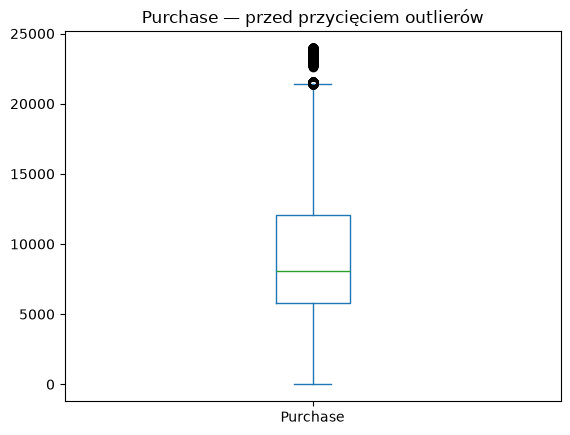

In [17]:
df.Purchase.plot(kind='box')
plt.title('Purchase — przed przycięciem outlierów')
plt.show()

### Leczenie wartości odstających (przycinanie / clipping)

Nie usuwamy obserwacji — przycinamy wartości powyżej górnego odcięcia do `uc`.

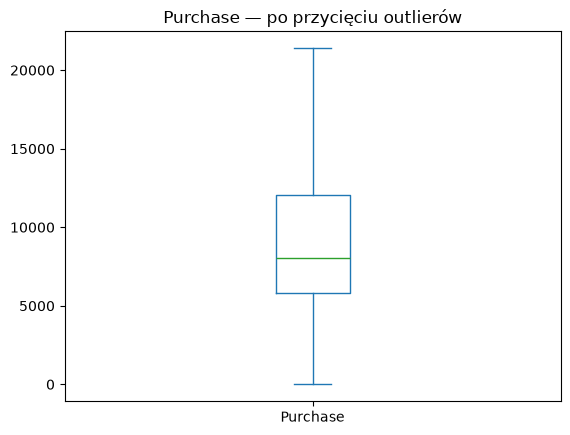

In [18]:
df['Purchase'] = df['Purchase'].clip(upper=uc)
df.Purchase.plot(kind='box')
plt.title('Purchase — po przycięciu outlierów')
plt.show()

## 6. Obsługa wartości brakujących

Dwa kroki: **wykrywanie** i **leczenie**.

In [19]:
df.isna()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,False,False,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,True,True,False
3,False,False,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
550063,False,False,False,False,False,False,False,False,False,True,True,False
550064,False,False,False,False,False,False,False,False,False,True,True,False
550065,False,False,False,False,False,False,False,False,False,True,True,False
550066,False,False,False,False,False,False,False,False,False,True,True,False


### Procent brakujących wartości w każdej zmiennej

In [20]:
missing_pct = (df.isna().sum() / df.shape[0] * 100).sort_values(ascending=False)
missing_pct

Product_Category_3            69.672659
Product_Category_2            31.566643
User_ID                        0.000000
Product_ID                     0.000000
Age                            0.000000
Gender                         0.000000
Occupation                     0.000000
City_Category                  0.000000
Marital_Status                 0.000000
Stay_In_Current_City_Years     0.000000
Product_Category_1             0.000000
Purchase                       0.000000
dtype: float64

Braki występują w `Product_Category_2` (~31,5%) oraz `Product_Category_3` (~69,7%).

### Leczenie brakujących wartości

| Metoda | Kiedy |
|--------|--------|
| Upuść zmienną | bardzo duży % braków |
| Upuść obserwacje | mały % braków |
| Imputacja | umiarkowany % braków |

- `Product_Category_2` (~31%) → imputacja **modą** (zmienna kategoryczna)
- `Product_Category_3` (~70%) → **porzucenie zmiennej**

In [21]:
mode_pc2 = df.Product_Category_2.mode()[0]
print('Tryb Product_Category_2:', mode_pc2)

df['Product_Category_2'] = df['Product_Category_2'].fillna(mode_pc2)
df.isna().sum()

Tryb Product_Category_2: 8.0


User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2                 0
Product_Category_3            383247
Purchase                           0
dtype: int64

In [22]:
# Porzucenie kolumn z brakami (tu: Product_Category_3)
df.dropna(axis=1, inplace=True)
df.dtypes

User_ID                         int64
Product_ID                        str
Gender                            str
Age                               str
Occupation                      int64
City_Category                     str
Stay_In_Current_City_Years        str
Marital_Status                  int64
Product_Category_1              int64
Product_Category_2            float64
Purchase                      float64
dtype: object

In [23]:
print('Pozostałe zmienne:', list(df.columns))
print('Braki po leczeniu:', df.isna().sum().sum())

Pozostałe zmienne: ['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category', 'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1', 'Product_Category_2', 'Purchase']
Braki po leczeniu: 0


## 7. Analiza jednowymiarowa

Wykresy dla jednej zmiennej — rozkład (ciągłe) lub skład/częstotliwość (kategoryczne).

### Zmienne ciągłe — `Purchase`

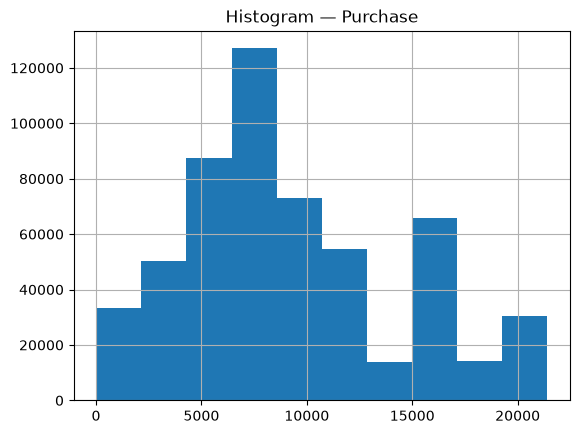

In [24]:
df.Purchase.hist()
plt.title('Histogram — Purchase')
plt.show()

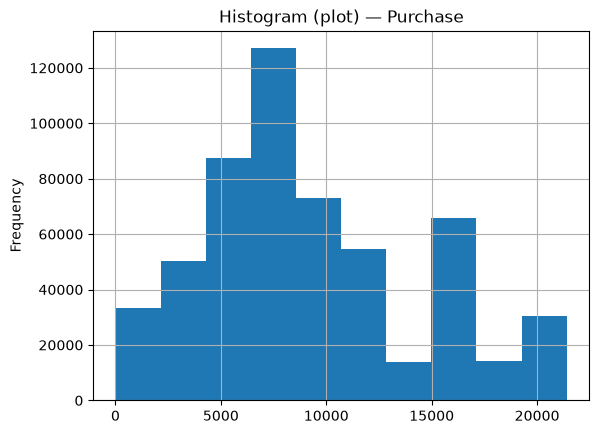

In [25]:
df.Purchase.plot(kind='hist', grid=True)
plt.title('Histogram (plot) — Purchase')
plt.show()

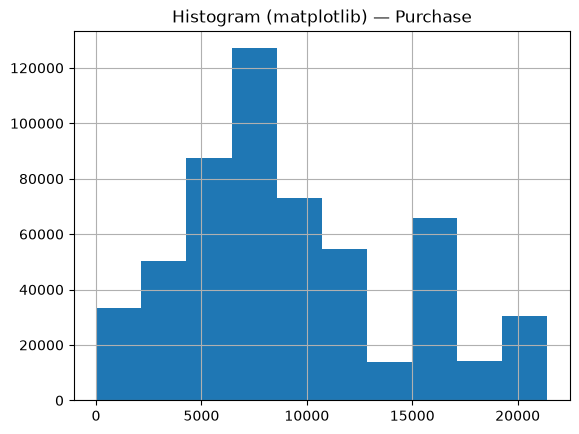

In [26]:
plt.hist(df.Purchase)
plt.grid(True)
plt.title('Histogram (matplotlib) — Purchase')
plt.show()

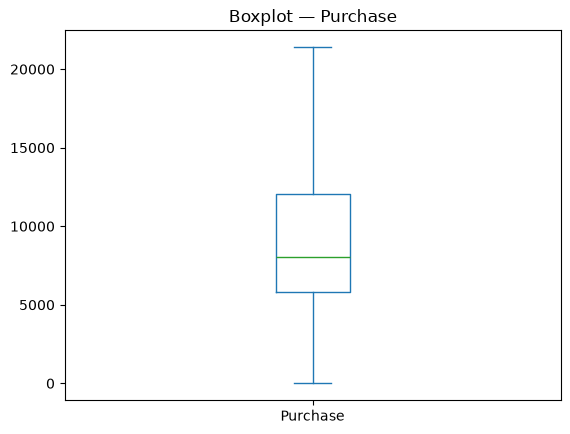

In [27]:
df.Purchase.plot(kind='box')
plt.title('Boxplot — Purchase')
plt.show()

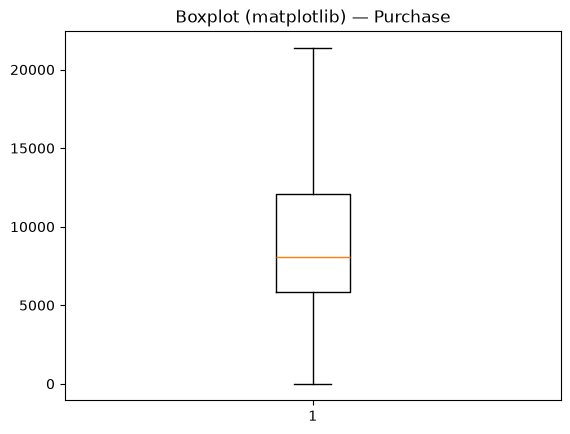

In [28]:
plt.boxplot(df.Purchase)
plt.title('Boxplot (matplotlib) — Purchase')
plt.show()

### Zmienne kategoryczne

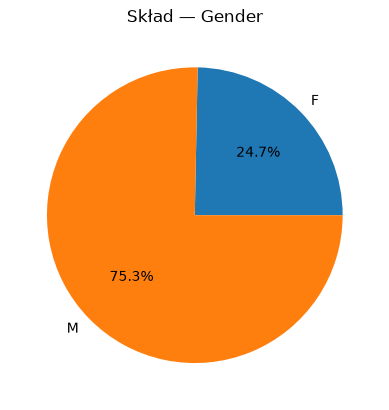

In [29]:
# Skład płci
df.groupby('Gender').City_Category.count().plot(kind='pie', autopct='%1.1f%%')
plt.title('Skład — Gender')
plt.ylabel('')
plt.show()

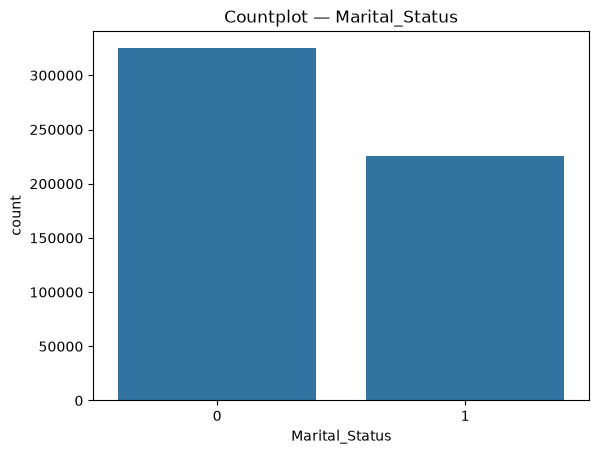

In [30]:
# Dystrybucja stanu cywilnego
sns.countplot(x=df.Marital_Status)
plt.title('Countplot — Marital_Status')
plt.show()

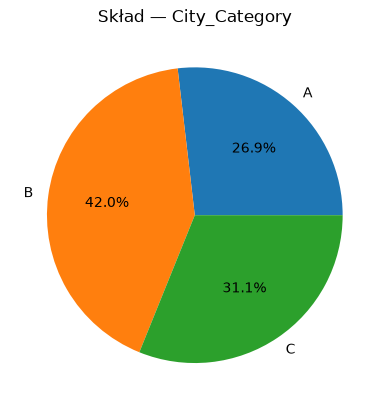

In [31]:
# Skład — kategoria miasta
df.groupby('City_Category').City_Category.count().plot(kind='pie', autopct='%1.1f%%')
plt.title('Skład — City_Category')
plt.ylabel('')
plt.show()

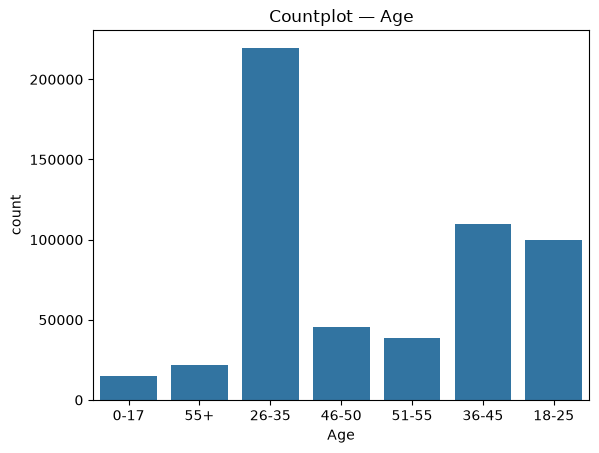

In [32]:
# Rozkład wieku
sns.countplot(x=df.Age)
plt.title('Countplot — Age')
plt.show()

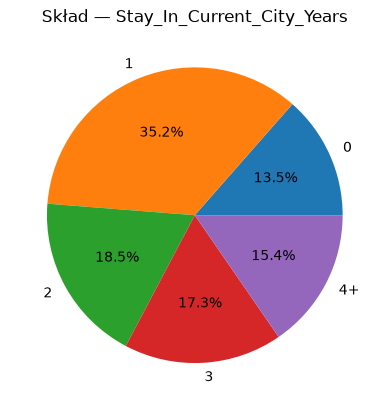

In [33]:
# Przebywanie w aktualnym miejscu zamieszkania
df.groupby('Stay_In_Current_City_Years').City_Category.count().plot(kind='pie', autopct='%1.1f%%')
plt.title('Skład — Stay_In_Current_City_Years')
plt.ylabel('')
plt.show()

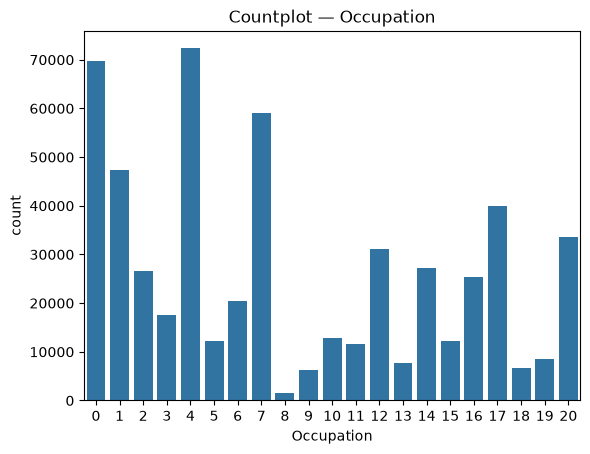

In [34]:
# Podział zawodowy
sns.countplot(x=df.Occupation)
plt.title('Countplot — Occupation')
plt.show()

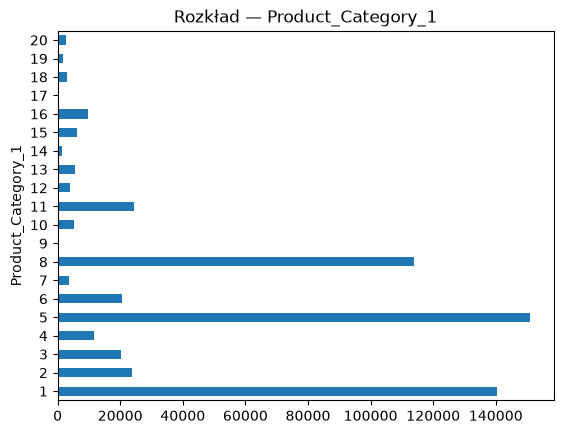

In [35]:
# Dystrybucja Product_Category_1
df.groupby('Product_Category_1').City_Category.count().plot(kind='barh')
plt.title('Rozkład — Product_Category_1')
plt.show()

## 8. Analiza dwuwymiarowa

Trzy przypadki: numeryczne–numeryczne, numeryczne–kategoryczne, kategoryczne–kategoryczne.

### Numeryczne i numeryczne

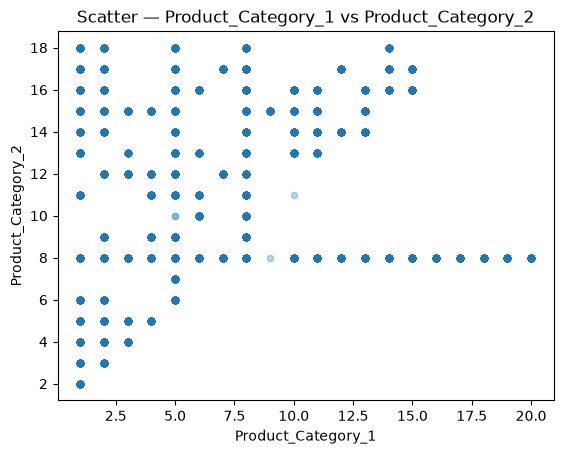

In [36]:
# Wykres punktowy (hipotetycznie traktujemy kategorie produktów jako numeryczne)
df.plot(x='Product_Category_1', y='Product_Category_2', kind='scatter', alpha=0.3)
plt.title('Scatter — Product_Category_1 vs Product_Category_2')
plt.show()

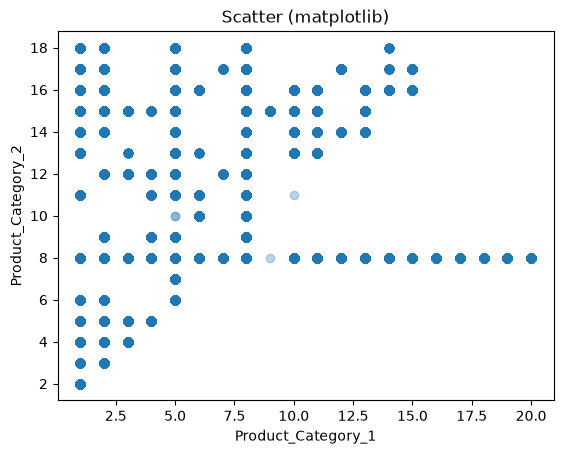

In [37]:
plt.scatter(x=df.Product_Category_1, y=df.Product_Category_2, alpha=0.3)
plt.xlabel('Product_Category_1')
plt.ylabel('Product_Category_2')
plt.title('Scatter (matplotlib)')
plt.show()

In [38]:
# Macierz korelacji
corr = df.select_dtypes(['float64', 'int64']).corr()
corr

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Purchase
User_ID,1.000000,-0.023971,0.020443,0.003825,0.002065,0.004608
Occupation,-0.023971,1.000000,0.024280,-0.007618,0.001566,0.020853
Marital_Status,0.020443,0.024280,1.000000,0.019888,0.010260,-0.000599
Product_Category_1,0.003825,-0.007618,0.019888,1.000000,0.279247,-0.347413
Product_Category_2,0.002065,0.001566,0.010260,0.279247,1.000000,-0.131104
Purchase,0.004608,0.020853,-0.000599,-0.347413,-0.131104,1.000000


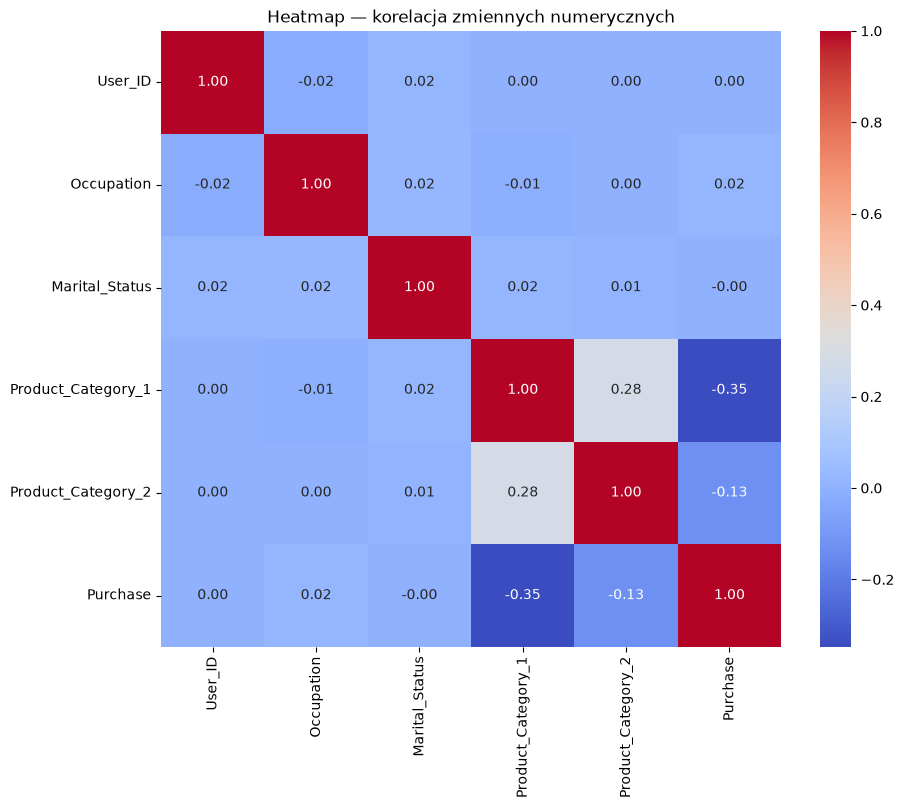

In [39]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(['float64', 'int64']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Heatmap — korelacja zmiennych numerycznych')
plt.show()

### Numeryczne i kategoryczne

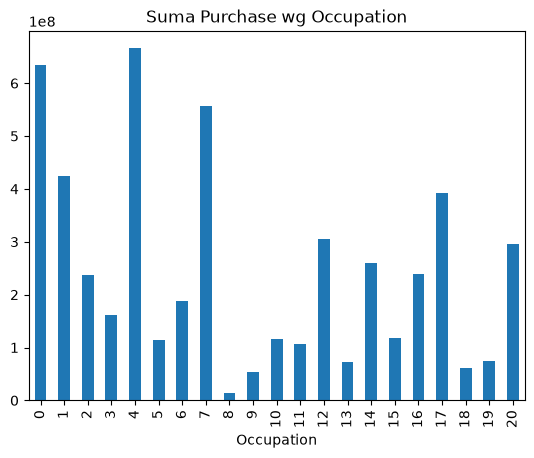

In [40]:
# Purchase vs Occupation — wykres słupkowy
df.groupby('Occupation').Purchase.sum().plot(kind='bar')
plt.title('Suma Purchase wg Occupation')
plt.show()

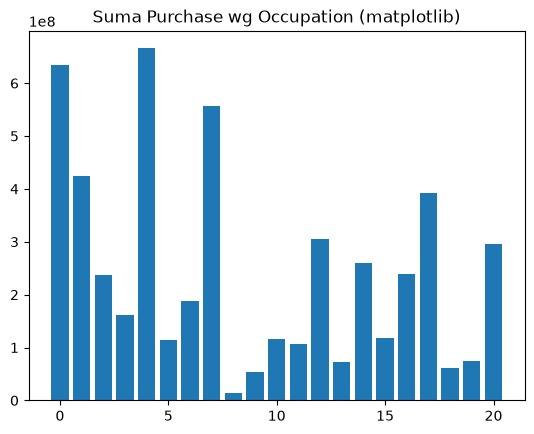

In [41]:
summary = df.groupby('Occupation').Purchase.sum()
plt.bar(x=summary.index, height=summary.values)
plt.title('Suma Purchase wg Occupation (matplotlib)')
plt.show()

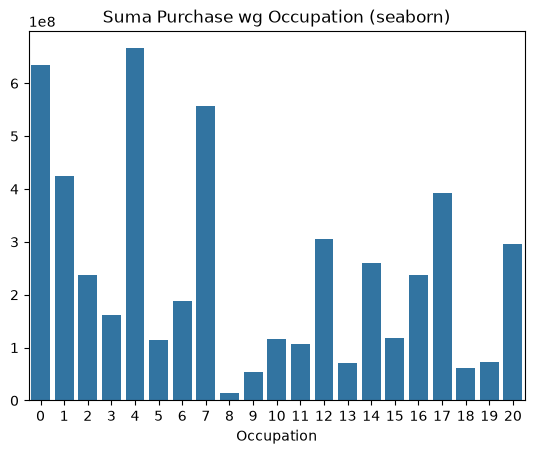

In [42]:
sns.barplot(x=summary.index, y=summary.values)
plt.title('Suma Purchase wg Occupation (seaborn)')
plt.show()

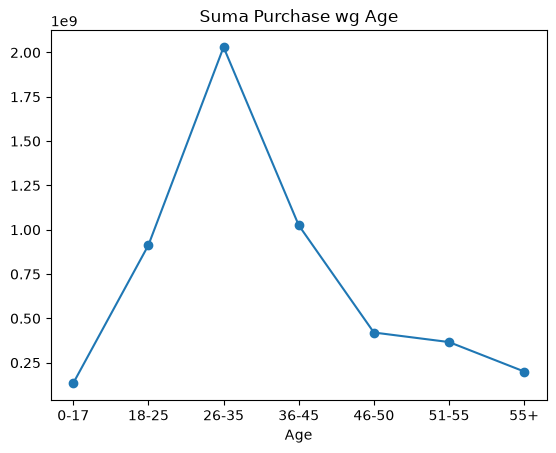

In [43]:
# Purchase vs Age — wykres liniowy
df.groupby('Age').Purchase.sum().plot(kind='line', marker='o')
plt.title('Suma Purchase wg Age')
plt.show()

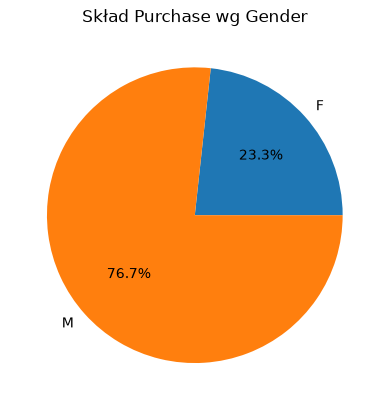

In [44]:
# Skład Purchase wg Gender — pie
df.groupby('Gender').Purchase.sum().plot(kind='pie', autopct='%1.1f%%')
plt.title('Skład Purchase wg Gender')
plt.ylabel('')
plt.show()

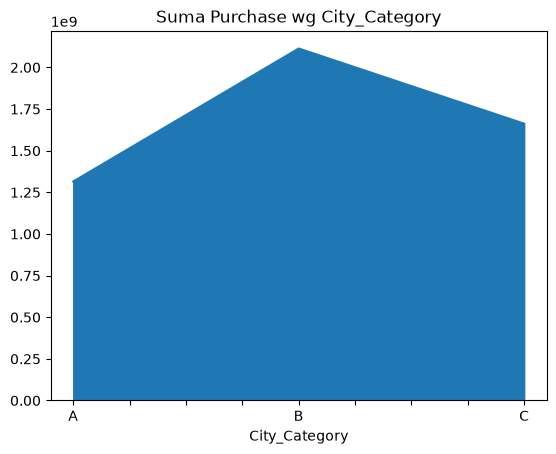

In [45]:
# Purchase vs City_Category — area
df.groupby('City_Category').Purchase.sum().plot(kind='area')
plt.title('Suma Purchase wg City_Category')
plt.show()

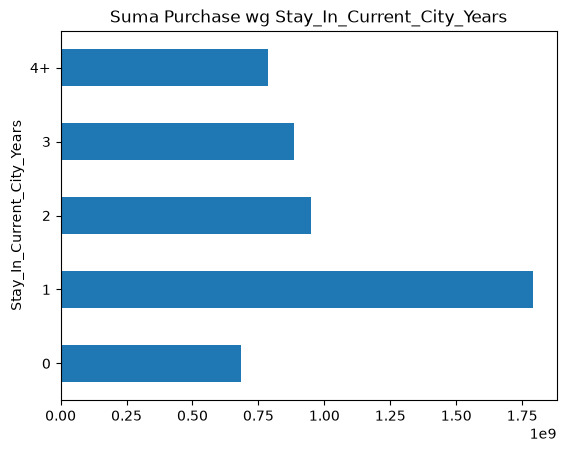

In [46]:
# Purchase vs Stay_In_Current_City_Years — barh
df.groupby('Stay_In_Current_City_Years').Purchase.sum().plot(kind='barh')
plt.title('Suma Purchase wg Stay_In_Current_City_Years')
plt.show()

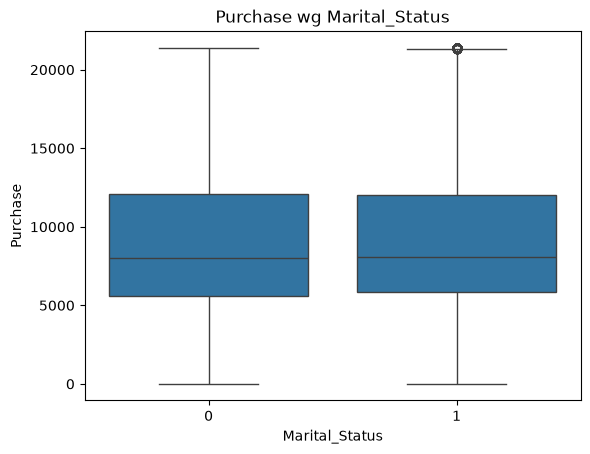

In [47]:
# Purchase vs Marital_Status — boxplot
sns.boxplot(x='Marital_Status', y='Purchase', data=df)
plt.title('Purchase wg Marital_Status')
plt.show()

### Kategoryczne i kategoryczne

In [48]:
# Związek Age × Gender
pd.crosstab(df.Age, df.Gender)

Gender,F,M
Age,,
0-17,5083,10019
18-25,24628,75032
26-35,50752,168835
36-45,27170,82843
46-50,13199,32502
51-55,9894,28607
55+,5083,16421


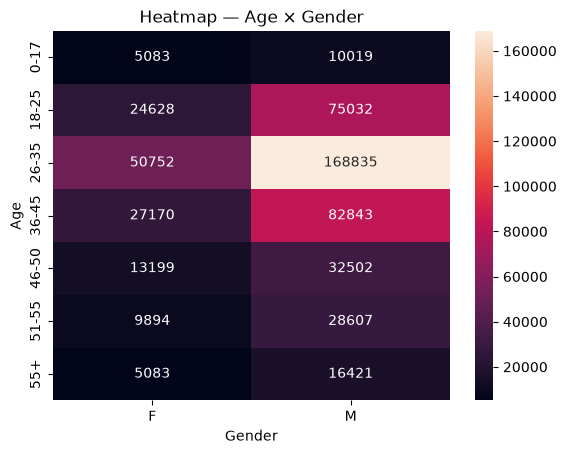

In [49]:
sns.heatmap(pd.crosstab(df.Age, df.Gender), annot=True, fmt='d')
plt.title('Heatmap — Age × Gender')
plt.show()

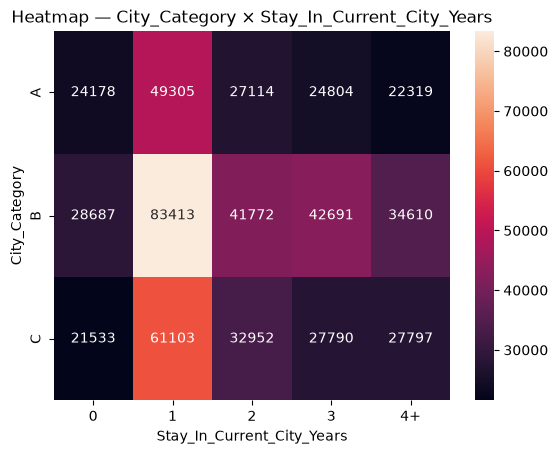

In [50]:
# Związek City_Category × Stay_In_Current_City_Years
sns.heatmap(pd.crosstab(df.City_Category, df.Stay_In_Current_City_Years), annot=True, fmt='d')
plt.title('Heatmap — City_Category × Stay_In_Current_City_Years')
plt.show()

---
## Podsumowanie EDA

1. **Struktura:** zestaw Black Friday — transakcje zakupowe z atrybutami użytkownika i produktu.
2. **Duplikaty:** brak zduplikowanych wierszy; `User_ID` naturalnie się powtarza.
3. **Outliery:** w `Purchase` wykryto wartości odstające od góry (IQR) — przycięto do `uc`.
4. **Braki:** `Product_Category_2` uzupełniono modą; `Product_Category_3` usunięto (>50% braków).
5. **Jedno-/dwuwymiarowa:** rozkłady zmiennych oraz relacje Purchase z Occupacją, wiekiem, płcią, miastem itd.